<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/lab-003c-jax.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 003c <br>
<hr/>

# Lab 003c — JAX basics

## JAX and its role in this course
JAX is a Python library from Google for numerical computing. Its arrays follow the NumPy interface (Lab 002), and four kinds of **function transformations** are added on top of it:

| transformation | input | output |
|---|---|---|
| `jax.jit` | a Python function | the same function, compiled by XLA (Accelerated Linear Algebra compiler) |
| `jax.grad` | a scalar function $f(x)$ | the function $\nabla f(x)$ (automatic differentiation) |
| `jax.vmap` | a function of one example | the same function acting on a batch of examples |
| `jax.lax.scan` and related primitives | a loop body | a loop that can be compiled |

The transformations compose: `jit(vmap(grad(f)))` is a compiled function that returns the gradient of `f` for every example of a batch. This is the style of the later labs of the course (Monte Carlo sampling of spin models, autoencoders, phase diagrams). Networks are built with **Flax NNX** (the module library of Flax) and trained with the optimiser library **Optax**.

The price for these transformations is a stricter programming model than in NumPy or PyTorch (Lab 003): arrays are **immutable**, random numbers need an **explicit key**, and functions passed to `jit` should be **pure** (output determined by the input, no side effects). Every section below introduces one of these rules together with the reason for it.

We begin with the differences between `jax.numpy` and NumPy (Section 1) and with explicit random keys (Section 2). Sections 3–5 introduce the three central transformations, `jit` (tracing and compilation), automatic differentiation and `vmap` (automatic batching). Section 6 shows how loops and branches are expressed inside compiled code, and Section 7 how JAX handles nested containers of arrays (pytrees). Section 8 builds, trains and modifies a network with Flax NNX and Optax. Section 9 collects common pitfalls and their fixes, and Section 10 combines all tools in a Metropolis sampler of the 2D Ising model, tested against exact enumeration. Section 11 is a table of corresponding operations in NumPy, JAX and PyTorch, and Section 12 lists references.

> To run this notebook in Google Colab, follow these steps:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (the first code cell sets `JAX_PLATFORMS=cpu`).
> 2. `jax`, `flax`, `optax`, `numpy` and `matplotlib` are pre-installed in Colab; no `pip install` required.
> 3. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"         # run JAX on the CPU (must be set before importing jax)
os.environ["CUDA_VISIBLE_DEVICES"] = ""     # hide all GPUs

import copy, time, tempfile
from functools import partial
import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
from jax import lax
import flax
from flax import nnx
import optax

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})

t_start = time.time()
print("JAX", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__)
print("devices:", jax.devices())

JAX 0.11.0 | flax 0.12.8 | optax 0.2.6


devices: [CpuDevice(id=0)]


<hr/>
## 1. `jax.numpy` and NumPy

`jax.numpy` (imported as `jnp`) re-implements the NumPy interface on top of XLA, so most of Lab 002 carries over by replacing `np.` with `jnp.`. Three differences matter in practice: arrays cannot be modified in place, the default floating-point type is 32-bit, and arrays live on a **device** (CPU = central processing unit, GPU = graphics processing unit, or TPU = tensor processing unit).

### 1.1 Common interface
We build the same $3\times4$ array in NumPy and in JAX and apply the same operations (reshape, mean along an axis, broadcasting, matrix product).

In [2]:
a_np = np.arange(12.0).reshape(3, 4)            # NumPy array, shape (3, 4)
a_jx = jnp.arange(12.0).reshape(3, 4)           # JAX array,   shape (3, 4)

# the same expression in both libraries: column means, centring by broadcasting, Gram matrix (3, 3)
res_np = (a_np - a_np.mean(axis=0)) @ (a_np - a_np.mean(axis=0)).T
res_jx = (a_jx - a_jx.mean(axis=0)) @ (a_jx - a_jx.mean(axis=0)).T

print("type of the JAX array      :", type(a_jx).__name__)
print("Gram matrix (JAX), shape   :", res_jx.shape)
print("max |NumPy - JAX|          :", float(np.max(np.abs(res_np - np.asarray(res_jx)))))
assert np.allclose(res_np, res_jx)

type of the JAX array      : ArrayImpl
Gram matrix (JAX), shape   : (3, 3)
max |NumPy - JAX|          : 0.0


### 1.2 Immutable arrays and `.at[...]`
A JAX array cannot be changed after it is created. `x[0] = 1.0` raises an error; the functional replacement `x.at[0].set(1.0)` returns a **new** array with the change and leaves `x` untouched. Inside `jit` the compiler turns this into an in-place update whenever the old array is no longer used, so no copy is paid for.

The reason is that `jit`, `grad` and `vmap` analyse a function as a mathematical map from inputs to outputs, and hidden modifications of inputs would break this analysis.

In [3]:
x = jnp.zeros(5)                                 # shape (5,)
try:
    x[0] = 1.0
except TypeError as err:
    print("TypeError:", str(err).split(".")[0])

y = x.at[0].set(1.0)                             # new array: y[0] = 1
y = y.at[1:3].add(10.0)                          # y[1:3] += 10
y = y.at[jnp.array([3, 3, 4])].add(1.0)          # repeated indices accumulate: y[3] += 2, y[4] += 1
print("x (unchanged):", x)
print("y            :", y)
assert float(x.sum()) == 0.0 and np.allclose(y, [1, 10, 10, 2, 1])

TypeError: JAX arrays are immutable and do not support in-place item assignment


x (unchanged): [0. 0. 0. 0. 0.]
y            : [ 1. 10. 10.  2.  1.]


Other methods of `.at[...]`: `.multiply`, `.min`, `.max`, `.get`. The repeated-index behaviour of `.add` (accumulation) is the same as NumPy's `np.add.at`, and differs from `y[idx] += 1` in NumPy, which adds only once per distinct index.

### 1.3 Data types
JAX uses 32-bit numbers by default (single precision, about 7 significant digits), because GPUs and TPUs are much faster in single precision. NumPy uses `float64` (about 16 digits). Requests for `float64` are truncated to `float32` (with a warning) unless 64-bit mode is switched on with `jax.config.update("jax_enable_x64", True)` (or the environment variable `JAX_ENABLE_X64=1` before the import).

Below we switch the mode on, compute $1 + 10^{-10} - 1$ in both precisions, and switch it off again (the rest of the notebook runs in `float32`).

In [4]:
print("default dtype of jnp.array(1.0)    :", jnp.array(1.0).dtype)
print("default dtype of np.array(1.0)     :", np.array(1.0).dtype)
print("1 + 1e-10 - 1 in float32           :", float(jnp.array(1.0) + 1e-10 - 1.0))

jax.config.update("jax_enable_x64", True)        # 64-bit mode on
z64 = jnp.array(1.0, dtype=jnp.float64)
print("dtype with x64 enabled             :", z64.dtype)
print("1 + 1e-10 - 1 in float64           :", float(z64 + 1e-10 - 1.0))
jax.config.update("jax_enable_x64", False)       # back to the default

default dtype of jnp.array(1.0)    : float32
default dtype of np.array(1.0)     : float64
1 + 1e-10 - 1 in float32           : 0.0


dtype with x64 enabled             : float64


1 + 1e-10 - 1 in float64           : 1.000000082740371e-10


`float32` is precise enough for training networks. For quantities that need many digits (energies of quantum systems to $10^{-10}$, long time evolutions, comparisons with exact results), enable 64-bit mode at the top of the notebook, before any array is created.

### 1.4 Devices
Every JAX array is stored on a device. `jax.devices()` lists the available devices, `x.devices()` tells where an array lives, and `jax.device_put` moves it. In this notebook only the CPU is visible. On a machine with a GPU, the same code runs there without changes when `JAX_PLATFORMS` is not set.

Conversion to NumPy (`np.asarray(x)`) copies the array to the host memory; it is cheap on the CPU but costs a transfer from a GPU.

In [5]:
cpu = jax.devices("cpu")[0]
v = jax.device_put(np.ones(3), cpu)              # NumPy -> JAX array on the CPU, shape (3,)
print("array lives on      :", v.devices())
print("back to NumPy, type :", type(np.asarray(v)).__name__)

array lives on      : {CpuDevice(id=0)}
back to NumPy, type : ndarray


<hr/>
## 2. Explicit randomness: PRNG keys

NumPy keeps a hidden global state of the random-number generator: every call to `np.random.normal` modifies it. Hidden state is a side effect, and it is incompatible with compiled, parallel and differentiated functions: the result of a function would depend on how many random numbers were drawn before, possibly on another device. JAX therefore uses a **PRNG (pseudo-random number generator) key**: a small array that is passed explicitly, so that the random output of a function is determined by its arguments.

### 2.1 Keys, `split` and reproducibility
Three rules govern the use of keys. The same key gives the same numbers, always. A key is therefore **used once**: for new numbers, `jax.random.split` derives independent new keys from an old one. Finally, `jax.random.fold_in(key, i)` derives a key from an integer, e.g. the index of a chain, a step or an epoch.

In [6]:
key = jax.random.key(0)                          # root key from the seed 0
a1 = jax.random.normal(key, (3,))
a2 = jax.random.normal(key, (3,))                # same key  -> same numbers
print("same key twice    :", a1, a2)
assert jnp.array_equal(a1, a2)

key, sub = jax.random.split(key)                 # standard idiom: keep `key` for later, use `sub` now
b = jax.random.normal(sub, (3,))
print("after split       :", b)

keys = jax.random.split(jax.random.key(0), 4)    # four independent keys, e.g. for four Monte Carlo chains
print("4 keys, shape     :", keys.shape)

k_epoch = [jax.random.fold_in(jax.random.key(0), i) for i in range(3)]   # one key per epoch index
print("uniform numbers from fold_in(key, 0..2):", [round(float(jax.random.uniform(k)), 4) for k in k_epoch])

same key twice    : [ 1.6226422   2.0252647  -0.43359444] [ 1.6226422   2.0252647  -0.43359444]


after split       : [-2.4424558  -2.0356805   0.20554423]
4 keys, shape     : (4,)


uniform numbers from fold_in(key, 0..2): [0.8423, 0.0073, 0.9024]


### 2.2 Statistics of the samples
To confirm that the keys produce the requested distributions, we draw $10^6$ samples of $\mathcal N(\mu=2, \sigma=0.5)$ and of the uniform distribution on $[0,1)$. The estimated moments must agree with the exact values within a few standard errors ($\sigma/\sqrt{N} = 5\cdot10^{-4}$ for the Gaussian mean).

In [7]:
k1, k2 = jax.random.split(jax.random.key(1))
n = 1_000_000
g = 2.0 + 0.5 * jax.random.normal(k1, (n,))     # N(2, 0.5^2), shape (n,)
u = jax.random.uniform(k2, (n,))                 # U[0, 1),      shape (n,)
print(f"Gaussian: mean = {float(g.mean()):.4f} (exact 2.0000), std = {float(g.std()):.4f} (exact 0.5000)")
print(f"uniform : mean = {float(u.mean()):.4f} (exact 0.5000), var = {float(u.var()):.4f} (exact {1/12:.4f})")
assert abs(float(g.mean()) - 2.0) < 5 * 0.5 / np.sqrt(n)

Gaussian: mean = 1.9995 (exact 2.0000), std = 0.4997 (exact 0.5000)
uniform : mean = 0.5000 (exact 0.5000), var = 0.0834 (exact 0.0833)


The rule that follows is to pass keys as arguments, split a key before every use and never reuse one. Reproducibility then comes for free: the same root seed gives the same run, also inside `jit` and `vmap`. Other samplers: `jax.random.bernoulli`, `randint`, `choice`, `permutation`, `categorical`.

<hr/>
## 3. `jit`: tracing and compilation

A NumPy-style expression such as `jnp.sum(jnp.tanh(x @ W) ** 2)` is executed operation by operation; every operation is a separate call with its own temporary array. `jax.jit` (JIT = just-in-time compilation) compiles the **whole function** with XLA, which fuses operations, removes temporaries, and runs the result as one program.

### 3.1 Tracing
On the first call, `jit` runs the Python function with **tracers**: placeholder objects that carry only the shape and the dtype of the arguments, not their values. Every `jnp` operation applied to a tracer is recorded. The record (a *jaxpr*, the intermediate representation of JAX) is compiled and stored in a cache keyed by the shapes and dtypes. Later calls with the same shapes and dtypes skip Python entirely and run the compiled code.

A Python `print` inside the function shows a tracer, and it runs only during tracing.

In [8]:
@jax.jit
def f(x):
    print("  [Python is running] x =", x)        # executed only while tracing
    return jnp.sin(x) ** 2 + jnp.cos(x) ** 2

print("first call :"); r1 = f(jnp.arange(3.0))
print("second call:"); r2 = f(jnp.arange(3.0) + 1.0)   # same shape and dtype: no tracing, no print
print("results    :", r1, r2)
print("the jaxpr of the same computation:")
print(jax.make_jaxpr(lambda x: jnp.sin(x) ** 2 + jnp.cos(x) ** 2)(jnp.arange(3.0)))

first call :
  [Python is running] x = JitTracer(float32[3])
second call:


results    : [1.         0.99999994 0.99999994] [0.99999994 0.99999994 1.        ]
the jaxpr of the same computation:
{ lambda ; a:f32[3]. let
    b:f32[3] = sin a
    c:f32[3] = integer_pow[y=2] b
    d:f32[3] = cos a
    e:f32[3] = integer_pow[y=2] d
    f:f32[3] = add c e
  in (f,) }


### 3.2 Timing of compiled code
Two rules apply when measuring the speed of JAX code. First, JAX dispatches work **asynchronously**: a call returns as soon as the computation is queued, so `.block_until_ready()` must be called on the result before stopping the clock. Second, the first call includes tracing and compilation, so it is timed separately from the later calls.

The test function is a three-layer $\tanh$ network applied to a batch: `x` has shape `(2000, 256)`, each `W` has shape `(256, 256)`, output shape `(2000, 256)`.

In [9]:
def mlp_forward(W1, W2, W3, x):
    h = jnp.tanh(x @ W1)
    h = jnp.tanh(h @ W2)
    return jnp.tanh(h @ W3)

kx, k1, k2, k3 = jax.random.split(jax.random.key(2), 4)
x_big = jax.random.normal(kx, (2000, 256))
W1, W2, W3 = (jax.random.normal(k, (256, 256)) / 16.0 for k in (k1, k2, k3))
mlp_forward_jit = jax.jit(mlp_forward)

def best_time(fun, *args, repeat=20):
    """Smallest wall time of `repeat` calls, in milliseconds (waits for the result)."""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter(); fun(*args).block_until_ready(); times.append(time.perf_counter() - t0)
    return 1e3 * min(times)

t0 = time.perf_counter(); mlp_forward_jit(W1, W2, W3, x_big).block_until_ready()
t_first = 1e3 * (time.perf_counter() - t0)
print(f"jit, first call (trace + compile + run) : {t_first:8.2f} ms")
print(f"jit, later calls (run only)              : {best_time(mlp_forward_jit, W1, W2, W3, x_big):8.2f} ms")
print(f"no jit (operation by operation)          : {best_time(mlp_forward, W1, W2, W3, x_big):8.2f} ms")
assert jnp.allclose(mlp_forward_jit(W1, W2, W3, x_big), mlp_forward(W1, W2, W3, x_big), atol=1e-5)

# second test: many small elementwise operations on a small array, x of shape (100,)
def many_small_ops(x):
    for _ in range(50):                                    # 50 iterations x 4 operations, unrolled at trace time
        x = 0.9 * jnp.sin(x) + 0.1 * jnp.cos(x)
    return x

many_small_ops_jit = jax.jit(many_small_ops)
x_small = jnp.linspace(0.0, 1.0, 100)
many_small_ops_jit(x_small).block_until_ready()            # compile once before timing
print(f"200 small operations, jit    : {best_time(many_small_ops_jit, x_small):8.3f} ms")
print(f"200 small operations, no jit : {best_time(many_small_ops, x_small):8.3f} ms")
assert jnp.allclose(many_small_ops_jit(x_small), many_small_ops(x_small), atol=1e-5)

jit, first call (trace + compile + run) :   123.91 ms
jit, later calls (run only)              :     5.37 ms


no jit (operation by operation)          :     3.32 ms


200 small operations, jit    :    0.103 ms


200 small operations, no jit :    3.406 ms


For a function dominated by three large matrix products, `jit` gains little or nothing: the matrix products are already optimised library calls in both cases. The gain is large for functions made of many small operations (a Monte Carlo step, a time step of a differential equation, a training step), where the cost of dispatching each operation from Python dominates; the second test in the cell above (200 elementwise operations on an array of 100 numbers) is such a case.

### 3.3 Static arguments and recompilation
The compiled code is specialised to the **shapes and dtypes** of the arguments. A new shape triggers a new trace and a new compilation. Arguments that are not arrays but change the *structure* of the computation (a number of iterations, a flag, the name of an activation) must be declared **static** with `static_argnums` or `static_argnames`: their value becomes part of the cache key, and a new value triggers recompilation.

We count traces with a Python counter, which is incremented only while tracing.

In [10]:
n_traces = 0

@partial(jax.jit, static_argnames="n_terms")
def exp_taylor(x, n_terms):
    """exp(x) from the first n_terms terms of its Taylor series; n_terms is a Python int (static)."""
    global n_traces
    n_traces += 1                                  # runs only during tracing
    term, total = jnp.ones_like(x), jnp.ones_like(x)
    for k in range(1, n_terms):                    # Python loop over a static number: unrolled at trace time
        term = term * x / k
        total = total + term
    return total

calls = [(jnp.ones(3), 10), (jnp.ones(3) * 2, 10), (jnp.ones(4), 10), (jnp.ones(3), 20), (jnp.ones(3), 10)]
for x_in, nt in calls:
    before = n_traces
    exp_taylor(x_in, n_terms=nt)
    print(f"shape {x_in.shape}, n_terms = {nt:2d} -> {'new trace + compile' if n_traces > before else 'cached'}")
print("total number of traces:", n_traces)
assert n_traces == 3
print("exp_taylor(1, 20) - e  :", float(exp_taylor(jnp.array(1.0), n_terms=20) - np.e), "(float32 rounding level)")

shape (3,), n_terms = 10 -> new trace + compile
shape (3,), n_terms = 10 -> cached
shape (4,), n_terms = 10 -> new trace + compile
shape (3,), n_terms = 20 -> new trace + compile
shape (3,), n_terms = 10 -> cached
total number of traces: 3


exp_taylor(1, 20) - e  : 2.384185791015625e-07 (float32 rounding level)


### 3.4 Value-dependent shapes
`jit` needs the **shape** of every intermediate array at trace time. Two kinds of code violate this. The first is code whose **output shapes depend on values**, such as `x[x > 0]` (boolean masking), `jnp.nonzero(x)` or `jnp.unique(x)`. The second is **Python control flow on values**, such as `if x > 0:` or `while err > tol:` on a traced array (Section 6).

The fixes keep the shapes fixed: compute on all entries and mask with `jnp.where`, or give the maximal size explicitly (`jnp.nonzero(x, size=..., fill_value=...)`).

In [11]:
@jax.jit
def sum_of_positive_bad(x):
    return x[x > 0].sum()                          # shape of x[x > 0] depends on the values of x

@jax.jit
def sum_of_positive(x):
    return jnp.where(x > 0, x, 0.0).sum()          # fixed shape: zero out the negative entries

x_test = jnp.array([-1.0, 2.0, -3.0, 4.0])
try:
    sum_of_positive_bad(x_test)
except Exception as err:
    print(type(err).__name__, ":", str(err).splitlines()[0][:110])
print("sum of positive entries with jnp.where:", float(sum_of_positive(x_test)), "(exact 6.0)")
idx = jax.jit(lambda x: jnp.nonzero(x > 0, size=4, fill_value=-1)[0])(x_test)
print("indices of positive entries (padded with -1):", idx)

NonConcreteBooleanIndexError : Array boolean indices must be concrete; got bool[4]
sum of positive entries with jnp.where: 6.0 (exact 6.0)


indices of positive entries (padded with -1): [ 1  3 -1 -1]


The practical rule is to compile whole steps (a training step, a Monte Carlo sweep), not single operations. Keep shapes fixed, mark structural Python arguments as static, and expect one compilation per distinct shape or static value.

<hr/>
## 4. Automatic differentiation

`jax.grad(f)` returns a new **function** that computes $\nabla f$ exactly (to floating-point precision), by applying the chain rule to the recorded operations. The mechanism (reverse mode, backpropagation) is the same as `loss.backward()` in PyTorch, derived in detail in Lab 004 (Automatic differentiation, Lecture 2). The interface differs: in PyTorch gradients are stored in `.grad` attributes of tensors; in JAX `grad` maps a function to a function, which can again be compiled, vectorised or differentiated.

### 4.1 `grad` and `value_and_grad` on a double-well potential
Double-well potential $V(x) = (x^2-1)^2$, with $V'(x) = 4x(x^2-1)$ and $V''(x) = 12x^2 - 4$. We compare automatic and analytic derivatives on a grid of 201 points in $[-1.5, 1.5]$; `vmap` (Section 5) evaluates the scalar function at every grid point.

max |V'_auto  - V'_exact | on the grid = 0.00e+00
max |V''_auto - V''_exact| on the grid = 9.54e-07


value_and_grad at x = 0.5: V = 0.5625 (exact 0.5625), V' = -1.5000 (exact -1.5000)


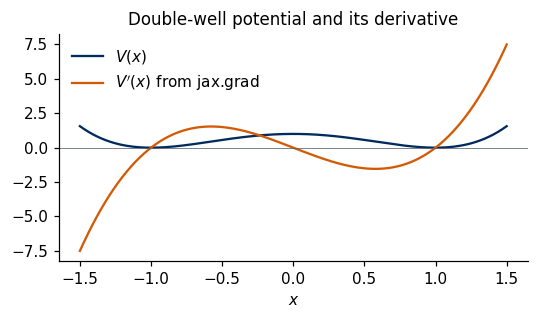

In [12]:
V   = lambda x: (x**2 - 1.0) ** 2                # scalar -> scalar
dV  = jax.grad(V)                                # first derivative, a new function
d2V = jax.grad(jax.grad(V))                      # second derivative: grad of grad

xs = jnp.linspace(-1.5, 1.5, 201)                # shape (201,)
err1 = jnp.max(jnp.abs(jax.vmap(dV)(xs)  - 4 * xs * (xs**2 - 1)))
err2 = jnp.max(jnp.abs(jax.vmap(d2V)(xs) - (12 * xs**2 - 4)))
print(f"max |V'_auto  - V'_exact | on the grid = {float(err1):.2e}")
print(f"max |V''_auto - V''_exact| on the grid = {float(err2):.2e}")

val, slope = jax.value_and_grad(V)(0.5)          # both in one pass: V(0.5) and V'(0.5)
print(f"value_and_grad at x = 0.5: V = {float(val):.4f} (exact 0.5625), V' = {float(slope):.4f} (exact -1.5000)")
assert err1 < 1e-5 and err2 < 1e-4

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(xs, V(xs), color=UJNavy, label="$V(x)$")
ax.plot(xs, jax.vmap(dV)(xs), color=DSOrange, label="$V'(x)$ from jax.grad")
ax.axhline(0, color=UJGray, lw=0.5); ax.set_xlabel("$x$"); ax.legend(); ax.set_title("Double-well potential and its derivative")
plt.tight_layout(); plt.show()

Two rules of `grad` follow from this example: the function must return a **scalar**, and the derivative is taken with respect to the **first** argument (`argnums=(0, 1)` selects others). Arguments must be floating-point: the gradient with respect to an integer is not defined.

### 4.2 Gradient and Hessian of a Gaussian log-density
For $\mathbf x\in\mathbb R^3$ and the Gaussian density with mean $\boldsymbol\mu$ and covariance $\Sigma$,
$$\log p(\mathbf x) = -\tfrac12 (\mathbf x-\boldsymbol\mu)^T\Sigma^{-1}(\mathbf x-\boldsymbol\mu) - \tfrac12\log\det(2\pi\Sigma),\qquad
\nabla\log p = -\Sigma^{-1}(\mathbf x-\boldsymbol\mu),\qquad \nabla^2\log p = -\Sigma^{-1}.$$
The gradient $\nabla \log p$ is called the **score**; it reappears in diffusion models and in Langevin sampling. `jax.hessian` returns the $3\times3$ matrix of second derivatives, which we compare with $-\Sigma^{-1}$.

In [13]:
mu    = jnp.array([1.0, -1.0, 0.5])                          # shape (3,)
A     = jnp.array([[2.0, 0.3, 0.0], [0.3, 1.0, 0.2], [0.0, 0.2, 0.5]])
Sigma = A @ A.T                                              # symmetric positive definite, (3, 3)
Sigma_inv = jnp.linalg.inv(Sigma)

def log_p(x):                                                # (3,) -> scalar
    d = x - mu
    return -0.5 * d @ Sigma_inv @ d - 0.5 * jnp.linalg.slogdet(2 * jnp.pi * Sigma)[1]

x0 = jnp.array([0.2, 0.4, -0.3])
score_auto = jax.grad(log_p)(x0)                             # (3,)
hess_auto  = jax.hessian(log_p)(x0)                          # (3, 3)
print("score, automatic :", score_auto)
print("score, analytic  :", -Sigma_inv @ (x0 - mu))
print("max |Hessian_auto - (-Sigma^-1)| =", float(jnp.max(jnp.abs(hess_auto + Sigma_inv))))
assert jnp.allclose(score_auto, -Sigma_inv @ (x0 - mu), rtol=1e-4, atol=1e-4)
assert jnp.allclose(hess_auto, -Sigma_inv, rtol=1e-4, atol=1e-4)

score, automatic : [ 0.9039935 -3.6418612  6.3390303]
score, analytic  : [ 0.9039935 -3.6418612  6.3390307]


max |Hessian_auto - (-Sigma^-1)| = 1.1920928955078125e-07


### 4.3 Jacobians: forward mode and reverse mode
For a vector function $\mathbf f:\mathbb R^n\to\mathbb R^m$, the Jacobian $J_{ij}=\partial f_i/\partial x_j$ has shape `(m, n)`. JAX offers two algorithms. `jax.jacfwd` uses **forward mode**, one pass per input direction, $n$ passes in total; it is efficient for $n \ll m$. `jax.jacrev` uses **reverse mode**, one pass per output component, $m$ passes in total; it is efficient for $m \ll n$. `grad` is the special case $m=1$, which is why training (one scalar loss, millions of parameters) uses reverse mode.

`jax.hessian` is implemented as `jacfwd(jacrev(f))`. As an example we take the map from polar to Cartesian coordinates, $\mathbf f(r,\varphi) = (r\cos\varphi, r\sin\varphi)$, whose Jacobian determinant is $\det J = r$.

In [14]:
def polar_to_cartesian(q):                       # (2,) -> (2,)
    r, phi = q
    return jnp.array([r * jnp.cos(phi), r * jnp.sin(phi)])

q0 = jnp.array([2.0, jnp.pi / 6])
J_fwd = jax.jacfwd(polar_to_cartesian)(q0)       # (2, 2)
J_rev = jax.jacrev(polar_to_cartesian)(q0)       # (2, 2)
J_exact = jnp.array([[jnp.cos(q0[1]), -q0[0] * jnp.sin(q0[1])],
                     [jnp.sin(q0[1]),  q0[0] * jnp.cos(q0[1])]])
print("Jacobian (jacfwd):\n", J_fwd)
print("max |jacfwd - exact| =", float(jnp.max(jnp.abs(J_fwd - J_exact))),
      "| max |jacrev - exact| =", float(jnp.max(jnp.abs(J_rev - J_exact))))
print(f"det J = {float(jnp.linalg.det(J_fwd)):.5f} (exact r = 2)")
assert jnp.allclose(J_fwd, J_exact, atol=1e-6) and jnp.allclose(J_rev, J_exact, atol=1e-6)

Jacobian (jacfwd):
 [[ 0.8660254 -1.       ]
 [ 0.5        1.7320508]]


max |jacfwd - exact| = 0.0 | max |jacrev - exact| = 0.0
det J = 2.00000 (exact r = 2)


To sum up the derivative tools: `grad` turns a scalar function into its gradient function; `value_and_grad` returns both in one pass (the loss is needed anyway for monitoring); `jacfwd`, `jacrev` and `hessian` give full derivative matrices. All of them return ordinary functions that can be compiled with `jit` and batched with `vmap`.

<hr/>
## 5. `vmap`: automatic batching

Code is often easiest to write for **one** example (one spin configuration, one particle, one data point). `jax.vmap(f)` turns such a function into one that acts on a whole batch, by adding a batch axis to every operation inside `f`. The result is the same as a Python loop over the examples, but it runs as one vectorised operation, without rewriting `f` with explicit batch indices.

### 5.1 `in_axes` and `out_axes`
`in_axes` says which axis of each argument is the batch axis (`None` = the argument is shared by all examples); `out_axes` says where the batch axis is placed in the output.

Example: the quadratic form $q(\mathbf x) = \mathbf x^T M\mathbf x$ written for one vector $\mathbf x$ of shape `(3,)`, applied to 5 vectors with a shared matrix $M$ of shape `(3, 3)`.

In [15]:
def quad_form(M, x):                             # M: (3, 3), x: (3,) -> scalar
    return x @ M @ x

M  = jnp.array([[2.0, 1.0, 0.0], [1.0, 3.0, 0.0], [0.0, 0.0, 1.0]])
Xb = jax.random.normal(jax.random.key(3), (5, 3))               # batch of 5 vectors, axis 0 = batch

q_vmap = jax.vmap(quad_form, in_axes=(None, 0))(M, Xb)          # M shared, x batched along axis 0 -> (5,)
q_loop = jnp.array([quad_form(M, x) for x in Xb])               # reference: Python loop
q_einsum = jnp.einsum("bi,ij,bj->b", Xb, M, Xb)                 # reference: hand-written batched formula
print("q from vmap :", q_vmap)
print("max |vmap - loop| =", float(jnp.max(jnp.abs(q_vmap - q_loop))),
      "| max |vmap - einsum| =", float(jnp.max(jnp.abs(q_vmap - q_einsum))))
assert jnp.allclose(q_vmap, q_loop, atol=1e-5)

# batch stored along axis 1 (input shape (3, 5)); outer products x x^T with the batch axis placed last
outer = jax.vmap(lambda x: jnp.outer(x, x), in_axes=1, out_axes=2)(Xb.T)
print("outer products, shape (3, 3, batch):", outer.shape)
assert jnp.allclose(outer[:, :, 4], jnp.outer(Xb[4], Xb[4]))

q from vmap : [6.9860296 6.53101   4.769985  3.367536  5.9823413]
max |vmap - loop| = 0.0 | max |vmap - einsum| = 0.0


outer products, shape (3, 3, batch): (3, 3, 5)


### 5.2 Many independent Monte Carlo chains at once
We sample the Boltzmann distribution $p(x)\propto e^{-V(x)/T}$ for the double-well potential of Section 4 with the Metropolis algorithm. One step for **one** chain at position $x$ proposes $x' = x + \delta\,\xi$ with $\xi\sim\mathcal N(0,1)$, and accepts it with probability $\min\!\big(1, e^{-[V(x')-V(x)]/T}\big)$; otherwise the chain stays at $x$.

The step takes a key and a scalar position. `vmap` over keys and positions runs $C = 2000$ chains in parallel: positions of shape `(C,)`, keys of shape `(C,)`. The loop over steps is still a Python loop around a compiled step here; Section 6 moves such loops into the compiled code.

To test the sampler, the exact $\langle x^2\rangle = \int x^2 e^{-V/T}dx \big/ \int e^{-V/T}dx$ is computed by quadrature on a fine grid and compared with the average over chains and steps.

In [16]:
T_dw, delta = 0.5, 0.8                            # temperature and proposal width

def metropolis_step(key, x):                      # key, scalar x -> scalar x
    k_prop, k_acc = jax.random.split(key)
    x_new = x + delta * jax.random.normal(k_prop)
    accept = jax.random.uniform(k_acc) < jnp.exp(-(V(x_new) - V(x)) / T_dw)
    return jnp.where(accept, x_new, x)            # no Python `if`: both branches have the same shape

step_all = jax.jit(jax.vmap(metropolis_step))     # (C,) keys, (C,) positions -> (C,) positions

n_chains, n_steps, n_burn = 2000, 600, 100
key = jax.random.key(4)
x_chains = jnp.zeros(n_chains)                    # all chains start at x = 0
x2_sum = jnp.zeros(n_chains)
for t in range(n_steps):
    key, sub = jax.random.split(key)
    x_chains = step_all(jax.random.split(sub, n_chains), x_chains)
    if t >= n_burn:
        x2_sum += x_chains**2                     # per-chain running sum, shape (C,)
x2_per_chain = x2_sum / (n_steps - n_burn)

grid = jnp.linspace(-4, 4, 20001)                 # quadrature grid for the exact value
w = jnp.exp(-V(grid) / T_dw)
x2_exact = float(jnp.sum(grid**2 * w) / jnp.sum(w))
x2_mc, x2_err = float(x2_per_chain.mean()), float(x2_per_chain.std() / np.sqrt(n_chains))
print(f"<x^2> Metropolis ({n_chains} chains) = {x2_mc:.4f} ± {x2_err:.4f}")
print(f"<x^2> exact (quadrature)           = {x2_exact:.4f}")
assert abs(x2_mc - x2_exact) < 5 * x2_err

<x^2> Metropolis (2000 chains) = 0.8532 ± 0.0010
<x^2> exact (quadrature)           = 0.8521


The error bar uses the spread of the per-chain averages: the chains are independent, so their averages are independent estimates.

### 5.3 Per-example gradients: `vmap` of `grad`
`grad` of a mean loss gives the gradient averaged over the batch. Some methods need the gradient of **every example separately** (studies of gradient noise, influence of single data points, differentially private training). In JAX this is `vmap(grad(loss_one))`.

We take a linear model $\hat y = \mathbf w\cdot\mathbf x$ with the loss of one example $\ell = \frac12(\mathbf w\cdot\mathbf x - y)^2$, whose gradient is $(\mathbf w\cdot\mathbf x - y)\,\mathbf x$. For a batch of $B=8$ examples with $\mathbf x$ of shape `(4,)` the result has shape `(8, 4)`, and each row is compared with the analytic formula.

In [17]:
def loss_one(w, x, y):                           # w: (4,), x: (4,), y: scalar
    return 0.5 * (w @ x - y) ** 2

kw, kx, ky = jax.random.split(jax.random.key(5), 3)
w0 = jax.random.normal(kw, (4,))
X8, Y8 = jax.random.normal(kx, (8, 4)), jax.random.normal(ky, (8,))

per_example = jax.vmap(jax.grad(loss_one), in_axes=(None, 0, 0))(w0, X8, Y8)   # (8, 4)
analytic = (X8 @ w0 - Y8)[:, None] * X8                                        # (8, 4)
mean_grad = jax.grad(lambda w: jnp.mean(jax.vmap(loss_one, in_axes=(None, 0, 0))(w, X8, Y8)))(w0)
print("per-example gradients, shape:", per_example.shape)
print("max |vmap(grad) - analytic|  =", float(jnp.max(jnp.abs(per_example - analytic))))
print("max |mean of per-example gradients - gradient of mean loss| =",
      float(jnp.max(jnp.abs(per_example.mean(0) - mean_grad))))
assert jnp.allclose(per_example, analytic, atol=1e-5) and jnp.allclose(per_example.mean(0), mean_grad, atol=1e-5)

per-example gradients, shape: (8, 4)


max |vmap(grad) - analytic|  = 0.0


max |mean of per-example gradients - gradient of mean loss| = 3.725290298461914e-08


The pattern of this section is: write the function for one example, add the batch with `vmap`, compile the result with `jit`. `in_axes=None` marks shared arguments (parameters, the matrix $M$); keys are batched like any other array.

<hr/>
## 6. Control flow inside `jit`

During tracing, an array argument is a tracer without a value. A Python `if x > 0:` needs a concrete `True` or `False` and fails. A Python `for` loop over a fixed range works, but it is **unrolled**: 10 000 iterations become 10 000 copies of the loop body in the compiled program, with long compilation times. `jax.lax` provides compiled control-flow primitives:

| need | primitive | remark |
|---|---|---|
| choose elementwise | `jnp.where(cond, a, b)` | computes both `a` and `b` |
| choose one of two functions | `lax.cond(pred, f_true, f_false, x)` | runs one branch (under `vmap`: both) |
| loop of fixed length, collect outputs | `lax.scan(body, carry, xs)` | the workhorse: time evolution, Monte Carlo sweeps |
| loop of fixed length, no outputs | `lax.fori_loop(lo, hi, body, init)` | |
| loop until a condition | `lax.while_loop(cond, body, init)` | not reverse-differentiable |

### 6.1 Python `if` on a traced value
The first cell shows the error raised by a Python `if` on a traced value, and the two compiled alternatives, `jnp.where` and `lax.cond`.

In [18]:
@jax.jit
def relu_bad(x):
    if x > 0:                                    # needs the value of x at trace time
        return x
    return 0.0 * x

try:
    relu_bad(jnp.array(2.0))
except jax.errors.TracerBoolConversionError as err:
    print("TracerBoolConversionError:", str(err).splitlines()[0][:100])

relu_where = jax.jit(lambda x: jnp.where(x > 0, x, 0.0))                             # elementwise choice
relu_cond  = jax.jit(lambda x: lax.cond(x > 0, lambda v: v, lambda v: jnp.zeros_like(v), x))   # scalar predicate
print("jnp.where on [-1, 2]:", relu_where(jnp.array([-1.0, 2.0])),
      "| lax.cond on -1 and 2:", float(relu_cond(-1.0)), float(relu_cond(2.0)))

TracerBoolConversionError: Attempted boolean conversion of traced array with shape bool[].


jnp.where on [-1, 2]: [0. 2.] | lax.cond on -1 and 2: 0.0 2.0


### 6.2 `lax.scan`: a loop with a carry
`lax.scan(body, carry0, xs)` runs
```python
carry = carry0
for x in xs:
    carry, y = body(carry, x)
    ys.append(y)
return carry, stack(ys)
```
as one compiled loop. The **carry** is the state passed from step to step (positions, a key, spin configurations); `y` is what is recorded at each step. `xs` can be `None` together with `length=n`.

As an example we follow random walks: $W=10\,000$ walkers in one dimension, $x_{t+1} = x_t + \xi_t$, $\xi_t\sim\mathcal N(0,1)$, $x_0=0$, for $T=400$ steps. The carry is `(key, x)` with `x` of shape `(W,)`; the recorded output is $\langle x_t^2\rangle$ per step, shape `(T,)`. The exact result is $\langle x_t^2\rangle = t$ (diffusion), and the figure compares the two.

<x_T^2> at T = 400: 399.0 (exact 400)
max relative deviation of <x_t^2>/t from 1 for t > 50: 0.019  (relative statistical error sqrt(2/W) = 0.014)


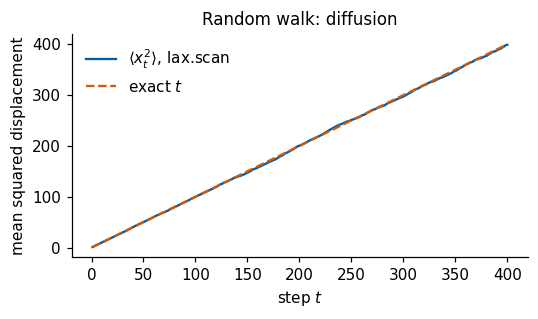

In [19]:
n_walkers, n_t = 10_000, 400

def walk_step(carry, _):
    key, x = carry                               # key, positions (W,)
    key, sub = jax.random.split(key)
    x = x + jax.random.normal(sub, x.shape)
    return (key, x), jnp.mean(x**2)              # new carry, recorded output (scalar)

@jax.jit
def random_walk(key):
    (_, x_final), msd = lax.scan(walk_step, (key, jnp.zeros(n_walkers)), xs=None, length=n_t)
    return x_final, msd                          # (W,), (T,)

x_final, msd = random_walk(jax.random.key(6))
t_axis = np.arange(1, n_t + 1)
rel_dev = np.max(np.abs(np.asarray(msd) / t_axis - 1)[50:])
print(f"<x_T^2> at T = {n_t}: {float(msd[-1]):.1f} (exact {n_t})")
print(f"max relative deviation of <x_t^2>/t from 1 for t > 50: {rel_dev:.3f}"
      f"  (relative statistical error sqrt(2/W) = {np.sqrt(2/n_walkers):.3f})")
assert rel_dev < 6 * np.sqrt(2 / n_walkers)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(t_axis, msd, color=UJBlue, label=r"$\langle x_t^2\rangle$, lax.scan")
ax.plot(t_axis, t_axis, "--", color=DSOrange, label="exact $t$")
ax.set_xlabel("step $t$"); ax.set_ylabel("mean squared displacement"); ax.legend(); ax.set_title("Random walk: diffusion")
plt.tight_layout(); plt.show()

The Metropolis chains of Section 5.2 can be rewritten the same way, with the carry `(key, x_chains)`; Section 10 does this for the Ising model.

### 6.3 `fori_loop` and `while_loop`
`lax.fori_loop(lo, hi, body, init)` runs a loop of fixed length with `body(i, state) -> state`. We use it for **power iteration**, $\mathbf v\leftarrow A\mathbf v/\|A\mathbf v\|$, which converges to the eigenvector of the eigenvalue of largest modulus; the result is compared with `jnp.linalg.eigvalsh`.
`lax.while_loop(cond, body, init)` stops when `cond(state)` is `False`, so the number of iterations is decided at run time. We use it for **Newton's method** for the minimum $x=1$ of the double well, $x\leftarrow x - V'(x)/V''(x)$, until $|V'(x)|<10^{-6}$; the derivatives come from `jax.grad`.

In [20]:
A_sym = jnp.array([[4.0, 1.0, 0.0], [1.0, 3.0, 1.0], [0.0, 1.0, 2.0]])     # symmetric (3, 3)

@jax.jit
def power_iteration(A):
    def body(i, v):
        w = A @ v
        return w / jnp.linalg.norm(w)
    v = lax.fori_loop(0, 200, body, jnp.ones(A.shape[0]))      # 200 iterations
    return v @ A @ v                                            # Rayleigh quotient

lam_power = float(power_iteration(A_sym))
lam_exact = float(jnp.linalg.eigvalsh(A_sym)[-1])
print(f"largest eigenvalue: power iteration = {lam_power:.5f}, eigvalsh = {lam_exact:.5f}")
assert abs(lam_power - lam_exact) < 1e-4

@jax.jit
def newton_minimum(x0):
    def cond(state):
        x, it = state
        return (jnp.abs(dV(x)) > 1e-6) & (it < 50)
    def body(state):
        x, it = state
        return x - dV(x) / d2V(x), it + 1
    return lax.while_loop(cond, body, (x0, 0))

x_min, n_it = newton_minimum(jnp.array(2.0))
print(f"Newton from x0 = 2: x_min = {float(x_min):.6f} (exact 1) after {int(n_it)} iterations")
assert abs(float(x_min) - 1.0) < 1e-5

largest eigenvalue: power iteration = 4.73205, eigvalsh = 4.73205
Newton from x0 = 2: x_min = 1.000000 (exact 1) after 6 iterations


Inside `jit`, therefore, `jnp.where` or `lax.cond` replace `if` on values; `lax.scan` serves loops that record a trajectory, `fori_loop` fixed-length loops, and `while_loop` loops with a run-time stopping condition. Python `if`/`for` remain fine on **static** quantities (shapes, Python integers, flags).

<hr/>
## 7. Pytrees: nested containers of arrays

The parameters of a network are not one array but a collection: one weight matrix and one bias per layer. JAX handles such collections as **pytrees**: nested Python lists, tuples and dictionaries (and registered classes, such as the states of Flax modules) whose **leaves** are arrays. All transformations accept pytrees: `grad` with respect to a pytree of parameters returns a pytree of gradients **with the same structure**.

As an example we store the parameters of a two-layer perceptron, with layer sizes $2\to16\to1$, as a list of dictionaries.

In [21]:
def init_params(key, sizes):
    """List of {'W': (n_in, n_out), 'b': (n_out,)} dictionaries, one per layer."""
    keys = jax.random.split(key, len(sizes) - 1)
    return [{"W": jax.random.normal(k, (n_in, n_out)) / jnp.sqrt(n_in), "b": jnp.zeros(n_out)}
            for k, n_in, n_out in zip(keys, sizes[:-1], sizes[1:])]

def mlp_apply(params, x):                        # x: (B, 2) -> (B, 1)
    for layer in params[:-1]:
        x = jnp.tanh(x @ layer["W"] + layer["b"])
    return x @ params[-1]["W"] + params[-1]["b"]

params = init_params(jax.random.key(7), [2, 16, 1])
print("structure           :", jax.tree_util.tree_structure(params))
print("shapes of the leaves:", jax.tree_util.tree_map(jnp.shape, params))
n_par = sum(leaf.size for leaf in jax.tree_util.tree_leaves(params))
print("number of parameters:", n_par, "(exact 2*16 + 16 + 16*1 + 1 =", 2*16 + 16 + 16 + 1, ")")
assert n_par == 65

structure           : PyTreeDef([{'W': *, 'b': *}, {'W': *, 'b': *}])
shapes of the leaves: [{'W': (2, 16), 'b': (16,)}, {'W': (16, 1), 'b': (1,)}]
number of parameters: 65 (exact 2*16 + 16 + 16*1 + 1 = 65 )


`tree_map(f, tree1, tree2, ...)` applies `f` leaf by leaf to trees of equal structure. One step of gradient descent $\theta\leftarrow\theta - \eta\nabla_\theta L$ on **all** parameters is therefore one line. The cell defines a mean squared error (MSE) loss on a toy target $y = x_1 x_2$ with 256 points (inputs `(256, 2)`, targets `(256, 1)`), computes the gradient pytree, and runs 200 compiled gradient-descent steps; the loss should decrease.

In [22]:
kx = jax.random.key(8)
X_toy = jax.random.uniform(kx, (256, 2), minval=-1, maxval=1)    # (256, 2)
Y_toy = (X_toy[:, 0] * X_toy[:, 1])[:, None]                      # (256, 1)

def mse(params, X, Y):
    return jnp.mean((mlp_apply(params, X) - Y) ** 2)

grads = jax.grad(mse)(params, X_toy, Y_toy)
print("gradient has the structure of params:",
      jax.tree_util.tree_structure(grads) == jax.tree_util.tree_structure(params))

@jax.jit
def gd_step(params, lr=0.2):
    loss, g = jax.value_and_grad(mse)(params, X_toy, Y_toy)
    return jax.tree_util.tree_map(lambda p, gp: p - lr * gp, params, g), loss

loss_0 = float(mse(params, X_toy, Y_toy))
for _ in range(200):
    params, loss = gd_step(params)
loss_200 = float(mse(params, X_toy, Y_toy))
print(f"MSE before training = {loss_0:.4f}, after 200 gradient-descent steps = {loss_200:.4f}")
assert loss_200 < loss_0

gradient has the structure of params: True


MSE before training = 0.2903, after 200 gradient-descent steps = 0.0048


Parameters, gradients, optimiser states and Monte Carlo states are all pytrees. `tree_map` applies an update leaf by leaf, `tree_leaves` lists the arrays (for counting or norms), and `tree_structure` compares layouts. Flax and Optax (next section) are built on this.

<hr/>
## 8. Flax NNX and Optax: a network, its training and its layers

Keeping parameter dictionaries ourselves (Section 7) becomes tedious for deep networks. **Flax NNX** provides layers as Python objects, close to `torch.nn.Module` (Lab 003): a module holds its parameters as attributes (`nnx.Param` variables) and is called like a function. **Optax** provides optimisers (stochastic gradient descent (SGD), Adam, learning-rate schedules, gradient clipping) as pure functions on pytrees.

### 8.1 A multilayer perceptron
We define a multilayer perceptron (MLP) $1\to32\to32\to1$ with $\tanh$ activations. Random initialisation needs keys; `nnx.Rngs(seed)` is a container that hands out a fresh key to each layer. Input shape `(B, 1)`, output shape `(B, 1)`.

In [23]:
class MLP(nnx.Module):
    def __init__(self, d_in, d_hidden, d_out, *, rngs):
        self.hidden1 = nnx.Linear(d_in, d_hidden, rngs=rngs)
        self.hidden2 = nnx.Linear(d_hidden, d_hidden, rngs=rngs)
        self.out     = nnx.Linear(d_hidden, d_out, rngs=rngs)

    def __call__(self, x):                       # x: (B, d_in) -> (B, d_out)
        x = jnp.tanh(self.hidden1(x))
        x = jnp.tanh(self.hidden2(x))
        return self.out(x)

model = MLP(1, 32, 1, rngs=nnx.Rngs(0))
print("output shape for a batch of 5:", model(jnp.ones((5, 1))).shape)
print("hidden1.kernel shape:", model.hidden1.kernel[...].shape, "| out.bias shape:", model.out.bias[...].shape)

output shape for a batch of 5: (5, 1)
hidden1.kernel shape: (1, 32) | out.bias shape: (1,)


### 8.2 A compiled training step
We fit a toy regression problem, $y = \sin(2x) + \varepsilon$ with noise $\varepsilon\sim\mathcal N(0, 0.1^2)$ on $x\in[-2,2]$, 256 training points, shapes `(256, 1)`.

The training step combines three components. `nnx.value_and_grad(loss_fn)(model, x, y)` returns the loss and the gradient with respect to the parameters of `model` (a state with the same structure as the parameters). `nnx.Optimizer(model, optax.adam(lr), wrt=nnx.Param)` keeps the Adam state for the parameters, and `optimizer.update(model, grads)` changes the parameters of `model` in place. `nnx.jit` is `jax.jit` for functions that take NNX modules: it splits the modules into arrays before compilation and writes the updated arrays back afterwards.

A good fit reaches a training MSE close to the noise variance $0.01$, and its MSE against the noise-free curve on a test grid is well below $0.01$; these are the two numbers to look for in the output.

training MSE: first step = 0.6770, last step = 0.0085 (noise variance 0.0100)
MSE against the noise-free curve on the grid = 0.0003


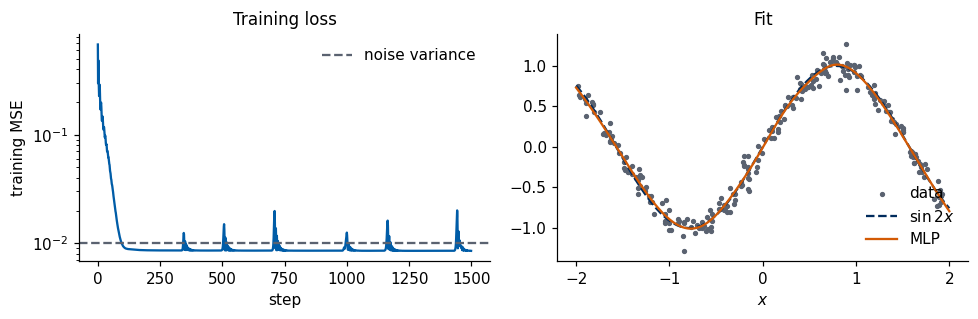

In [24]:
k_x, k_n = jax.random.split(jax.random.key(9))
x_train = jax.random.uniform(k_x, (256, 1), minval=-2, maxval=2)        # (256, 1)
y_train = jnp.sin(2 * x_train) + 0.1 * jax.random.normal(k_n, (256, 1))  # (256, 1)
x_grid = jnp.linspace(-2, 2, 200)[:, None]                               # (200, 1)

def loss_fn(model, x, y):
    return jnp.mean((model(x) - y) ** 2)

@nnx.jit
def train_step(model, optimizer, x, y):
    loss, grads = nnx.value_and_grad(loss_fn)(model, x, y)
    optimizer.update(model, grads)               # Adam step, parameters of `model` updated in place
    return loss

model = MLP(1, 32, 1, rngs=nnx.Rngs(0))
optimizer = nnx.Optimizer(model, optax.adam(1e-2), wrt=nnx.Param)
losses = [float(train_step(model, optimizer, x_train, y_train)) for _ in range(1500)]   # full-batch training

mse_clean = float(jnp.mean((model(x_grid) - jnp.sin(2 * x_grid)) ** 2))
print(f"training MSE: first step = {losses[0]:.4f}, last step = {losses[-1]:.4f} (noise variance 0.0100)")
print(f"MSE against the noise-free curve on the grid = {mse_clean:.4f}")
assert losses[-1] < 0.02 and mse_clean < 0.005

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].semilogy(losses, color=UJBlue); axs[0].axhline(0.01, ls="--", color=UJGray, label="noise variance")
axs[0].set_xlabel("step"); axs[0].set_ylabel("training MSE"); axs[0].legend(); axs[0].set_title("Training loss")
axs[1].scatter(x_train[:, 0], y_train[:, 0], s=6, color=UJGray, label="data")
axs[1].plot(x_grid[:, 0], jnp.sin(2 * x_grid[:, 0]), "--", color=UJNavy, label=r"$\sin 2x$")
axs[1].plot(x_grid[:, 0], model(x_grid)[:, 0], color=DSOrange, label="MLP")
axs[1].set_xlabel("$x$"); axs[1].legend(); axs[1].set_title("Fit")
plt.tight_layout(); plt.show()

### 8.3 Freezing a subset of parameters with a `wrt` filter
A **filter** selects variables of a model by type and by path. Training only some parameters needs the filter in two places: in the gradient (`argnums=nnx.DiffState(0, wrt)` differentiates the first argument only with respect to the selected variables) and in the optimiser (`wrt=` keeps optimiser state only for them).

Below only the output layer `out` (kernel and bias, 33 numbers) is trained, on a new target $y = \sin(2x) + 0.5$: the hidden layers stay a fixed feature extractor, and the output layer has to shift the prediction up by $0.5$. If the freezing works, the hidden weights are bit-for-bit unchanged, and the prediction on the test grid has moved up by about $0.5$.

In [25]:
only_out = nnx.All(nnx.Param, nnx.PathContains("out"))           # parameters whose path contains "out"
opt_out = nnx.Optimizer(model, optax.adam(1e-2), wrt=only_out)

@nnx.jit
def train_step_out(model, optimizer, x, y):
    loss, grads = nnx.value_and_grad(loss_fn, argnums=nnx.DiffState(0, only_out))(model, x, y)
    optimizer.update(model, grads)
    return loss

W_hidden_before = model.hidden1.kernel[...].copy()                # copies of the arrays before training
b_out_before = model.out.bias[...].copy()
pred_before = model(x_grid)                                       # (200, 1)
y_shift = y_train + 0.5
for _ in range(300):
    loss_shift = train_step_out(model, opt_out, x_train, y_shift)

def count(model, flt):
    """Number of scalar parameters selected by the filter `flt`."""
    return sum(x.size for x in jax.tree_util.tree_leaves(nnx.state(model, flt)))

print("hidden1.kernel unchanged:", bool(jnp.array_equal(W_hidden_before, model.hidden1.kernel[...])))
print(f"out.bias: before = {float(b_out_before[0]):.4f}, after = {float(model.out.bias[...][0]):.4f}")
mean_shift = float(jnp.mean(model(x_grid) - pred_before))
print(f"mean shift of the prediction on the grid = {mean_shift:.4f} (target 0.5)")
print(f"training MSE on the shifted target = {float(loss_shift):.4f} (noise variance 0.0100)")
print("trainable parameters:", count(model, only_out), "of", count(model, nnx.Param))
assert jnp.array_equal(W_hidden_before, model.hidden1.kernel[...])
assert abs(mean_shift - 0.5) < 0.05

hidden1.kernel unchanged: True
out.bias: before = -0.1017, after = 0.1538
mean shift of the prediction on the grid = 0.4954 (target 0.5)
training MSE on the shifted target = 0.0087 (noise variance 0.0100)
trainable parameters: 33 of 1153


### 8.4 Working with the layers of a model
A trained network is an object that can be inspected and modified: we can list the layers, read and overwrite weights, replace or insert layers, separate the architecture from the numbers, save and restore. Below are the basic operations on the MLP trained above. `Lab_003b_Trained_models_toolbox_JAX.ipynb` (same folder) applies them in full to a trained convolutional network: kernels and feature maps, model surgery, transfer learning.

We start by walking the module tree. `nnx.iter_modules(model)` yields `(path, module)` for every submodule; `nnx.state(model, nnx.Param)` returns the parameters as a nested state, which `nnx.to_pure_dict` turns into a plain dictionary of arrays.

In [26]:
for path, module in nnx.iter_modules(model):
    name = "/".join(map(str, path)) or "(root)"
    print(f"{name:8s} {type(module).__name__:6s} parameters: {count(module, nnx.Param)}")

param_shapes = jax.tree_util.tree_map(jnp.shape, nnx.to_pure_dict(nnx.state(model, nnx.Param)))
print("parameter shapes:", param_shapes)

hidden1  Linear parameters: 64
hidden2  Linear parameters: 1056
out      Linear parameters: 33
(root)   MLP    parameters: 1153
parameter shapes: {'hidden1': {'bias': (32,), 'kernel': (1, 32)}, 'hidden2': {'bias': (32,), 'kernel': (32, 32)}, 'out': {'bias': (1,), 'kernel': (32, 1)}}


A parameter is an `nnx.Param` variable; `layer.kernel[...]` reads its array, and `layer.kernel[...] = new_array` overwrites it (the shape must stay the same). For example, setting the output bias to zero shifts every prediction by exactly minus the old bias, which the cell verifies.

In [27]:
y_before = model(x_grid)                                         # (200, 1)
b_old = model.out.bias[...].copy()                               # (1,)
model.out.bias[...] = jnp.zeros_like(b_old)                      # overwrite one layer's weights
shift = model(x_grid) - y_before
print(f"old bias = {float(b_old[0]):.4f}; prediction shift: min = {float(shift.min()):.4f}, max = {float(shift.max()):.4f}")
assert jnp.allclose(shift, -b_old, atol=1e-6)
model.out.bias[...] = b_old                                      # restore

old bias = 0.1538; prediction shift: min = -0.1538, max = -0.1538


Layers can also be replaced and inserted. A submodule is an attribute, so assigning a new `nnx.Linear` replaces it; the forward pass uses whatever is stored there. As an example we give a copy of the model a new output layer with 3 outputs instead of 1 (e.g. for a new task with three targets).

To **insert** a layer, the model must allow it. With `nnx.Sequential` the layers form a list, and a new model can be assembled from the trained layers plus new ones. To confirm that the insertion is done right, we insert a new linear layer initialised to the identity (kernel $=\mathbb 1$, bias $=0$) without an activation; it must not change the output.

In [28]:
model3 = copy.deepcopy(model)                                    # work on a copy, keep `model` intact
model3.out = nnx.Linear(32, 3, rngs=nnx.Rngs(1))                 # replace the output layer: 32 -> 3
print("output shape after replacing `out`:", model3(x_grid).shape)
assert jnp.array_equal(model3.hidden1.kernel[...], model.hidden1.kernel[...])   # the body is unchanged

# the same trained layers as an nnx.Sequential, then a new 32 -> 32 identity layer inserted before the output
identity = nnx.Linear(32, 32, rngs=nnx.Rngs(2))
identity.kernel[...] = jnp.eye(32)
identity.bias[...] = jnp.zeros(32)
layers = [model.hidden1, jnp.tanh, model.hidden2, jnp.tanh, model.out]
seq_deeper = nnx.Sequential(*layers[:4], identity, layers[4])
print("layers after insertion:", ["Linear" if isinstance(l, nnx.Linear) else "tanh" for l in layers[:4] + [identity, layers[4]]])
print("max |deeper - original| on the grid:", float(jnp.max(jnp.abs(seq_deeper(x_grid) - model(x_grid)))))
assert jnp.allclose(seq_deeper(x_grid), model(x_grid), atol=1e-5)

output shape after replacing `out`: (200, 3)


layers after insertion: ['Linear', 'tanh', 'Linear', 'tanh', 'Linear', 'Linear']
max |deeper - original| on the grid: 0.0


The architecture and the numbers of a model can be separated with `nnx.split` and `nnx.merge`. `nnx.split(model)` returns a `GraphDef` (the architecture: which layers, how they are connected, no arrays) and a `State` (all arrays, a pytree). `nnx.merge(graphdef, state)` builds a model again. This is how `nnx.jit` passes modules through `jax.jit`, and how parameters are saved: only the state is written to disk; the architecture is the Python class.

Below the parameters are saved as a `.npz` file in a temporary folder, loaded into a **freshly initialised** model (with different random weights), and the predictions are compared. Lab 003b shows checkpointing with Orbax, the library used for large models.

In [29]:
graphdef, state = nnx.split(model)
print("GraphDef type:", type(graphdef).__name__, "| number of arrays in the state:", len(jax.tree_util.tree_leaves(state)))
clone = nnx.merge(graphdef, state)
assert jnp.array_equal(clone(x_grid), model(x_grid))

# save: flatten {"hidden1": {"kernel": array, ...}, ...} to {"hidden1/kernel": array, ...}
pure = nnx.to_pure_dict(nnx.state(model, nnx.Param))
flat = {f"{layer}/{name}": np.asarray(arr) for layer, d in pure.items() for name, arr in d.items()}
path_npz = os.path.join(tempfile.mkdtemp(), "mlp_params.npz")
np.savez(path_npz, **flat)

# restore into a new model with different random initial weights
fresh = MLP(1, 32, 1, rngs=nnx.Rngs(123))
print("fresh model before loading, max |prediction difference| =", float(jnp.max(jnp.abs(fresh(x_grid) - model(x_grid)))))
loaded = np.load(path_npz)
restored = {}
for key_name in loaded.files:
    layer, name = key_name.split("/")
    restored.setdefault(layer, {})[name] = jnp.asarray(loaded[key_name])
fresh_state = nnx.state(fresh, nnx.Param)
nnx.replace_by_pure_dict(fresh_state, restored)                  # fill the state with the loaded arrays
nnx.update(fresh, fresh_state)                                   # write the state into the model
print("after loading,              max |prediction difference| =", float(jnp.max(jnp.abs(fresh(x_grid) - model(x_grid)))))
assert jnp.array_equal(fresh(x_grid), model(x_grid))

GraphDef type: GraphDef | number of arrays in the state: 6


fresh model before loading, max |prediction difference| = 1.5764353275299072
after loading,              max |prediction difference| = 0.0


Finally, the filters of Section 8.3 select parts of the state, for counting, for regularisation (e.g. weight decay on kernels only) or for freezing. `nnx.PathContains("kernel")` selects all weight matrices, `nnx.Not(...)` inverts a filter, and `nnx.All` and `nnx.Any` combine filters.

In [30]:
kernels = nnx.All(nnx.Param, nnx.PathContains("kernel"))
body = nnx.All(nnx.Param, nnx.Not(nnx.PathContains("out")))
print("all parameters       :", count(model, nnx.Param))
print("kernels only         :", count(model, kernels), "(exact 1*32 + 32*32 + 32*1 =", 32 + 1024 + 32, ")")
print("body (all but `out`) :", count(model, body), "| output layer:", count(model, only_out))
assert count(model, kernels) == 1088
assert count(model, body) + count(model, only_out) == count(model, nnx.Param)

all parameters       : 1153
kernels only         : 1088 (exact 1*32 + 32*32 + 32*1 = 1088 )
body (all but `out`) : 1120 | output layer: 33


An NNX model is thus a tree of modules whose leaves are `nnx.Param` variables. The tree can be walked (`iter_modules`), read and written (`layer.kernel[...]`), restructured (attribute assignment, `nnx.Sequential`), split into architecture and arrays (`nnx.split`/`nnx.merge`), and filtered (`nnx.All`, `nnx.PathContains`, `nnx.Not`); the same filters decide which parameters are trained.

<hr/>
## 9. Common pitfalls and their fixes

Each pitfall below is shown with its symptom and its fix.

### 9.1 In-place updates
`x[i] = v` raises `TypeError` (Section 1.2). The fix is `x = x.at[i].set(v)`.

### 9.2 Out-of-bounds indices
NumPy raises `IndexError` for an index outside the array. JAX cannot raise errors from compiled code and **clamps** the index for reading (and drops the update for `.at[...].set`), so no error appears. Index arithmetic must therefore be correct by construction (periodic boundaries: `% L` or `jnp.roll`).

In [31]:
arr = jnp.arange(5.0)
print("arr[10]              :", float(arr[10]), "(clamped to the last element, no error)")
print("arr.at[10].set(-1.0) :", arr.at[10].set(-1.0), "(update dropped, no error)")

arr[10]              : 4.0 (clamped to the last element, no error)
arr.at[10].set(-1.0) : [0. 1. 2. 3. 4.] (update dropped, no error)


### 9.3 Side effects inside `jit`
A Python `print` runs once, during tracing, and shows a tracer (Section 3.1). Appending to a global list or changing a global variable inside a compiled function also happens only at trace time. The fix is `jax.debug.print("{x}", x=x)`, which prints the runtime values at every call, and returning values instead of storing them in globals.

In [32]:
@jax.jit
def scaled(x):
    print("python print:", x)                              # once, at trace time, shows a tracer
    jax.debug.print("debug.print: sum = {s}", s=x.sum())   # every call, shows the value
    return 2 * x

for i in range(2):
    scaled(jnp.full(3, float(i)))

python print: JitTracer(~float32[3])
debug.print: sum = 0.0
debug.print: sum = 3.0


### 9.4 Python control flow on traced values
`if x > 0` inside `jit` raises `TracerBoolConversionError` (Section 6.1). The fix is `jnp.where`, `lax.cond` or `lax.while_loop`; or, if the quantity is a constant of the computation (a number of layers, a flag), declaring it static.

### 9.5 Recompilation inside a loop
`jax.jit(lambda ...)` placed inside a loop creates a **new** function object at every iteration, and each one is traced and compiled again. The same happens if the input shape changes at every iteration (e.g. a last mini-batch of different size). The fix is to define the compiled function once, outside the loop, and to keep shapes fixed (drop or pad the last batch). The cell compares the run times of the two versions.

In [33]:
x_vec = jnp.ones(1000)
t0 = time.perf_counter()
for i in range(20):
    jax.jit(lambda v: jnp.sin(v) * 2.0)(x_vec).block_until_ready()   # new function each time: 20 compilations
t_bad = time.perf_counter() - t0

f_once = jax.jit(lambda v: jnp.sin(v) * 2.0)                          # compiled once
t0 = time.perf_counter()
for i in range(20):
    f_once(x_vec).block_until_ready()
t_good = time.perf_counter() - t0
print(f"20 calls, jit inside the loop : {1e3*t_bad:7.1f} ms")
print(f"20 calls, jit defined once    : {1e3*t_good:7.1f} ms")

20 calls, jit inside the loop :  1478.7 ms
20 calls, jit defined once    :    67.3 ms


### 9.6 Mixing NumPy and JAX random numbers
`np.random` inside a compiled function is executed **once**, at trace time; the drawn number is stored in the compiled code as a constant, and every call returns the same "random" number. The fix is to pass a JAX key as an argument (Section 2).

In [34]:
@jax.jit
def noisy_bad(x):
    return x + np.random.normal()                     # drawn once, at trace time: frozen constant

@jax.jit
def noisy_good(key, x):
    return x + jax.random.normal(key)

print("np.random inside jit, 3 calls :", [round(float(noisy_bad(0.0)), 4) for _ in range(3)], "<- identical")
keys3 = jax.random.split(jax.random.key(10), 3)
print("jax.random with keys, 3 calls :", [round(float(noisy_good(k, 0.0)), 4) for k in keys3])

np.random inside jit, 3 calls : [-0.8823, -0.8823, -0.8823] <- identical


jax.random with keys, 3 calls : [1.1219, -1.808, -1.4439]


### 9.7 Precision of `float32`
Sums of many small numbers and differences of nearly equal numbers lose digits in the default `float32` (Section 1.3). The fix is to enable 64-bit mode at the top of the notebook when the precision matters.

<hr/>
## 10. Metropolis sampling of the 2D Ising model

All tools now come together in a Metropolis sampler of the ferromagnetic Ising model on an $L\times L$ square lattice with periodic boundary conditions (PBC),
$$E(\mathbf s) = -J\sum_{\langle ij\rangle} s_i s_j,\qquad s_i=\pm1,\qquad p(\mathbf s) = e^{-E(\mathbf s)/T}/Z,$$
with $J=1$ and $k_B=1$; the sum runs over nearest-neighbour pairs. The magnetisation per spin is $m = \frac1{L^2}\sum_i s_i$; we estimate $\langle|m|\rangle$.

The spins are updated in a checkerboard pattern. Colour the lattice like a chessboard. The neighbours of a black site are all white, so all black spins can be updated **at the same time** given the white spins, and then all white spins (this needs an even $L$ with PBC). One sweep = black half-sweep + white half-sweep. Flipping $s_i$ changes the energy by $\Delta E_i = 2Js_i h_i$, with $h_i$ the sum of the four neighbours, computed for all sites at once with `jnp.roll`. The flip is accepted with probability $\min(1, e^{-\Delta E_i/T})$.

The code has the structure of the previous sections: `sweep` acts on one lattice of shape `(L, L)`; `lax.scan` runs `n_sweeps` sweeps and records $|m|$ after each; `vmap` runs many independent chains; `jit` compiles everything. The complete sampler is the next cell.

In [35]:
def run_chain(key, s, beta, n_sweeps):
    """One Metropolis chain: s (L, L) of +-1, returns |m| after every sweep, shape (n_sweeps,)."""
    L = s.shape[0]
    black = (jnp.arange(L)[:, None] + jnp.arange(L)[None, :]) % 2 == 0          # (L, L) checkerboard mask

    def half_sweep(s, key, mask):
        h = jnp.roll(s, 1, 0) + jnp.roll(s, -1, 0) + jnp.roll(s, 1, 1) + jnp.roll(s, -1, 1)
        accept = jax.random.uniform(key, s.shape) < jnp.exp(-2.0 * beta * s * h)  # min(1, .) is implicit
        return jnp.where(mask & accept, -s, s)

    def sweep(s, key):
        k1, k2 = jax.random.split(key)
        s = half_sweep(half_sweep(s, k1, black), k2, ~black)
        return s, jnp.abs(s.mean())

    _, abs_m = lax.scan(sweep, s, jax.random.split(key, n_sweeps))
    return abs_m

# vmap over chains (keys and initial lattices batched, beta shared); n_sweeps is static (it fixes the loop length)
run_chains = jax.jit(jax.vmap(run_chain, in_axes=(0, 0, None, None)), static_argnums=3)

To know whether the sampler is correct, we need an exact reference. For the $4\times4$ lattice it can be obtained by enumeration: there are $2^{16} = 65\,536$ configurations. Configuration number $n$ is given by the binary digits of $n$ (bit $k$ → spin $k$, $0\to-1$, $1\to+1$); `vmap` computes the energy of all of them at once (array of shape `(65536, 4, 4)`). Then
$$\langle|m|\rangle = \frac{\sum_{\mathbf s}|m(\mathbf s)|\,e^{-E(\mathbf s)/T}}{\sum_{\mathbf s}e^{-E(\mathbf s)/T}},$$
with the minimal energy subtracted in the exponent to avoid overflow.

In [36]:
L = 4
n_conf = 2 ** (L * L)
bits = (jnp.arange(n_conf)[:, None] >> jnp.arange(L * L)[None, :]) & 1        # (65536, 16) of 0/1
configs = (2 * bits - 1).reshape(n_conf, L, L).astype(jnp.float32)          # (65536, 4, 4) of +-1

def energy(s):                                    # (L, L) -> scalar, PBC: each bond counted once
    return -jnp.sum(s * (jnp.roll(s, 1, 0) + jnp.roll(s, 1, 1)))

E_all = jax.vmap(energy)(configs)                 # (65536,)
absm_all = jnp.abs(configs.mean(axis=(1, 2)))     # (65536,)
print("ground-state energy:", float(E_all.min()), f"(exact -2 L^2 = {-2*L*L}),",
      "ground-state degeneracy:", int(jnp.sum(E_all == E_all.min())), "(exact 2)")
assert float(E_all.min()) == -2 * L * L and int(jnp.sum(E_all == E_all.min())) == 2

def exact_abs_m(T):
    w = jnp.exp(-(E_all - E_all.min()) / T)       # Boltzmann weights, shifted to avoid overflow
    return float(jnp.sum(absm_all * w) / jnp.sum(w))

ground-state energy: -32.0 (exact -2 L^2 = -32), ground-state degeneracy: 2 (exact 2)


We now compare the sampler with the exact values. We run $C=512$ chains from random initial lattices for $1000$ sweeps, of which the first $200$ are discarded (equilibration). The error bar is the standard deviation of the per-chain averages divided by $\sqrt C$ (independent chains). The temperatures lie below, near and above the critical temperature of the infinite lattice, $T_c = 2/\ln(1+\sqrt2)\approx 2.269$. The last column of the printout gives the deviation from the exact value in units of the error bar; for a correct sampler it should be of order one or two, as expected for statistical fluctuations, while a systematic error would show up as much larger values.

In [37]:
n_ch, n_sw, n_eq = 512, 1000, 200
temperatures = [1.5, 2.269, 3.0, 4.0]
k_init, k_run = jax.random.split(jax.random.key(11))
s0 = jax.random.choice(k_init, jnp.array([-1.0, 1.0]), (n_ch, L, L))      # (C, L, L) random start

t0 = time.perf_counter()
print("    T    <|m|> Metropolis    <|m|> exact   (MC - exact) / error")
results = []
for i, T in enumerate(temperatures):
    keys_T = jax.random.split(jax.random.fold_in(k_run, i), n_ch)          # one key per chain
    abs_m = run_chains(keys_T, s0, 1.0 / T, n_sw)                          # (C, n_sweeps)
    per_chain = abs_m[:, n_eq:].mean(axis=1)                               # (C,)
    mc, err, ex = float(per_chain.mean()), float(per_chain.std() / np.sqrt(n_ch)), exact_abs_m(T)
    results.append((T, mc, err, ex))
    print(f"{T:6.3f}   {mc:.4f} ± {err:.4f}     {ex:.4f}        {(mc - ex) / err:+.2f}")
print(f"time for {len(temperatures)} temperatures x {n_ch} chains x {n_sw} sweeps: {time.perf_counter() - t0:.2f} s")
assert all(abs(mc - ex) < 5 * err for T, mc, err, ex in results)

    T    <|m|> Metropolis    <|m|> exact   (MC - exact) / error


 1.500   0.9861 ± 0.0001     0.9862        -0.43


 2.269   0.8448 ± 0.0005     0.8439        +1.59


 3.000   0.6014 ± 0.0007     0.6013        +0.20


 4.000   0.4169 ± 0.0006     0.4182        -2.26
time for 4 temperatures x 512 chains x 1000 sweeps: 9.43 s


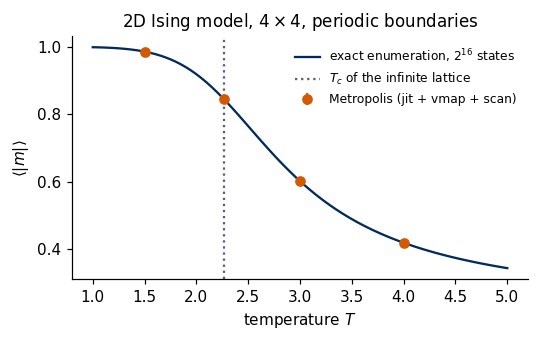

In [38]:
T_fine = np.linspace(1.0, 5.0, 81)
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(T_fine, [exact_abs_m(T) for T in T_fine], color=UJNavy, label="exact enumeration, $2^{16}$ states")
ax.errorbar([r[0] for r in results], [r[1] for r in results], yerr=[r[2] for r in results],
            fmt="o", color=DSOrange, label="Metropolis (jit + vmap + scan)")
ax.axvline(2 / np.log(1 + np.sqrt(2)), ls=":", color=UJGray, label=r"$T_c$ of the infinite lattice")
ax.set_xlabel("temperature $T$"); ax.set_ylabel(r"$\langle |m| \rangle$"); ax.legend(fontsize=8)
ax.set_title(r"2D Ising model, $4\times4$, periodic boundaries")
plt.tight_layout(); plt.show()

The sampler is the function for one lattice and one sweep, lifted by `lax.scan` (sweeps), `vmap` (chains) and `jit` (compilation); randomness enters only through keys. For a small system the exact answer is computable, and the sampler must reproduce it within its statistical error before it is trusted on large lattices, where no exact answer exists (Lab 018 in Lecture 5 continues from here).

<hr/>
## 11. Correspondence between NumPy, JAX and PyTorch

The table lists the operations of this notebook with their counterparts in NumPy and PyTorch, for quick reference.

| operation | NumPy | JAX | PyTorch |
|---|---|---|---|
| import | `import numpy as np` | `import jax, jax.numpy as jnp` | `import torch` |
| array from list | `np.array([1., 2.])` | `jnp.array([1., 2.])` | `torch.tensor([1., 2.])` |
| default float | `float64` | `float32` (`jax_enable_x64` for 64-bit) | `float32` |
| zeros, range, grid | `np.zeros`, `np.arange`, `np.linspace` | `jnp.zeros`, `jnp.arange`, `jnp.linspace` | `torch.zeros`, `torch.arange`, `torch.linspace` |
| set an element | `x[i] = v` | `x = x.at[i].set(v)` | `x[i] = v` |
| add to an element | `x[i] += v` | `x = x.at[i].add(v)` | `x[i] += v` |
| matrix product, einsum | `A @ B`, `np.einsum` | `A @ B`, `jnp.einsum` | `A @ B`, `torch.einsum` |
| conditional choice | `np.where(c, a, b)` | `jnp.where(c, a, b)` | `torch.where(c, a, b)` |
| seed | `rng = np.random.default_rng(0)` | `key = jax.random.key(0)` | `torch.manual_seed(0)` |
| normal samples | `rng.normal(size=n)` | `jax.random.normal(key, (n,))` | `torch.randn(n)` |
| new random stream | (automatic, hidden state) | `key, sub = jax.random.split(key)` | (automatic, hidden state) |
| to NumPy | — | `np.asarray(x)` | `x.detach().cpu().numpy()` |
| device | CPU only | `jax.device_put(x, device)` | `x.to("cuda")` |
| gradient | — | `jax.grad(f)(x)` | `y = f(x); y.backward(); x.grad` |
| loss and gradient | — | `jax.value_and_grad(f)(x)` | `loss.backward()` after the forward pass |
| Jacobian, Hessian | — | `jax.jacfwd`, `jax.jacrev`, `jax.hessian` | `torch.func.jacfwd`, `jacrev`, `hessian` |
| batch a function | — | `jax.vmap(f, in_axes=...)` | `torch.func.vmap(f, in_dims=...)` |
| compile | — | `jax.jit(f)` | `torch.compile(f)` |
| loop with state | Python `for` | `lax.scan`, `lax.fori_loop` | Python `for` |
| branch on a value | `if` | `jnp.where`, `lax.cond` | `if` |
| layer | — | `nnx.Linear(d_in, d_out, rngs=rngs)` | `nn.Linear(d_in, d_out)` |
| model class | — | `class M(nnx.Module)` | `class M(nn.Module)` |
| optimiser | — | `opt = nnx.Optimizer(model, optax.adam(lr), wrt=nnx.Param)` | `opt = torch.optim.Adam(model.parameters(), lr)` |
| one training step | — | `l, g = nnx.value_and_grad(loss)(model); opt.update(model, g)` | `opt.zero_grad(); loss.backward(); opt.step()` |
| freeze parameters | — | filter in `wrt=` and `nnx.DiffState` | `p.requires_grad_(False)` |
| list parameters | — | `nnx.state(model, nnx.Param)` | `model.named_parameters()` |
| save parameters | `np.save` | `nnx.state` + `np.savez`, or Orbax | `torch.save(model.state_dict(), path)` |
| print inside compiled code | — | `jax.debug.print("{x}", x=x)` | `print` |

The last cell prints the total run time of the notebook.

In [39]:
print(f"total run time of the notebook: {time.time() - t_start:.1f} s")

total run time of the notebook: 57.9 s


<hr/>
## 12. References
* JAX documentation: <https://docs.jax.dev>
  * Thinking in JAX: <https://docs.jax.dev/en/latest/notebooks/thinking_in_jax.html>
  * Just-in-time compilation: <https://docs.jax.dev/en/latest/jit-compilation.html>
  * Automatic differentiation: <https://docs.jax.dev/en/latest/automatic-differentiation.html>
  * Automatic vectorization: <https://docs.jax.dev/en/latest/automatic-vectorization.html>
  * Pseudorandom numbers: <https://docs.jax.dev/en/latest/random-numbers.html>
  * Control flow and logical operators with JIT: <https://docs.jax.dev/en/latest/control-flow.html>
  * Pytrees: <https://docs.jax.dev/en/latest/pytrees.html>
  * Common gotchas in JAX: <https://docs.jax.dev/en/latest/notebooks/Common_Gotchas_in_JAX.html>
* Flax NNX documentation: <https://flax.readthedocs.io/en/latest/>
  * NNX basics: <https://flax.readthedocs.io/en/latest/nnx_basics.html>
  * Filters: <https://flax.readthedocs.io/en/latest/guides/filters_guide.html>
* Optax documentation: <https://optax.readthedocs.io/en/latest/>